# DiabetesVision MLOps — 01 Data Exploration, Preprocessing and Training

**Dataset:** APTOS 2019 Blindness Detection · **Model:** MobileNetV2 · **Environment:** Google Colab

This corrected version keeps the original exploration and preprocessing sections, removes repeated setup/download/split cells, and organizes Experiment 1, fine-tuning (Experiment 2), and evaluation. Run cells from top to bottom.

> Educational/research use only. The model predicts diabetic retinopathy severity grades; it does not diagnose diabetes and is not a clinical diagnostic tool.

In [ ]:
# 0. Imports, GPU check, Colab paths, and dataset setup
import os, shutil, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from PIL import Image, ImageOps
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))
if not tf.config.list_physical_devices("GPU"):
    print("WARNING: Select Runtime > Change runtime type > T4 GPU if available.")

PROJECT_ROOT = Path("/content")
DATA_DIR = PROJECT_ROOT / "data" / "aptos"
TRAIN_CSV = DATA_DIR / "train.csv"
TRAIN_IMAGES = DATA_DIR / "train_images"
TEST_CSV = DATA_DIR / "test.csv"
TEST_IMAGES = DATA_DIR / "test_images"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Download only when the dataset is not already present.
if not TRAIN_CSV.exists() or not TRAIN_IMAGES.exists():
    kaggle_config = Path("/root/.kaggle/kaggle.json")
    if not kaggle_config.exists():
        from google.colab import files
        print("Upload kaggle.json when prompted. Never paste or share its contents.")
        uploaded = files.upload()

if not uploaded:
    raise FileNotFoundError("No Kaggle file was uploaded.")

uploaded_filename = next(iter(uploaded))

kaggle_config.parent.mkdir(parents=True, exist_ok=True)

shutil.copy(
    f"/content/{uploaded_filename}",
    kaggle_config
)

os.chmod(kaggle_config, 0o600)

print("Kaggle credentials configured successfully!")

TensorFlow: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Upload kaggle.json when prompted. Never paste or share its contents.


Saving kaggle.json to kaggle.json
Kaggle credentials configured successfully!


In [ ]:
!pip -q install kaggle
!kaggle competitions download -c aptos2019-blindness-detection -p /content/data

100% 9.51G/9.51G [01:45<00:00, 96.8MB/s]



In [ ]:
zip_path = Path("/content/data/aptos2019-blindness-detection.zip")

DATA_DIR.mkdir(parents=True, exist_ok=True)

In [ ]:
with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(DATA_DIR)

zip_path.unlink(missing_ok=True)

if not TRAIN_CSV.exists() or not TRAIN_IMAGES.exists():
    raise FileNotFoundError("APTOS train.csv/train_images not found. Check the extracted folder structure.")
df = pd.read_csv(TRAIN_CSV)
print("Dataset loaded:", df.shape)
print("Train images folder exists:", TRAIN_IMAGES.exists())
print("Test images folder exists:", TEST_IMAGES.exists())
display(df.head())


Dataset loaded: (3662, 2)
Train images folder exists: True
Test images folder exists: True


,id_code,diagnosis
0,000c1434d8d7,2
1,001639a390f0,4
2,0024cdab0c1e,1
3,002c21358ce6,0
4,005b95c28852,0


## 1. Dataset Overview

The APTOS 2019 dataset contains retinal fundus images
labeled according to diabetic retinopathy severity.

Each record contains:
- id_code: Unique image identifier
- diagnosis: Diabetic retinopathy severity (0–4)

This section explores the dataset structure and quality.

In [ ]:
# Dataset information

print("Dataset Information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate records:")
print(df.duplicated().sum())

print("\nUnique diagnosis classes:")
print(sorted(df["diagnosis"].unique()))

print("\nClass distribution:")
print(df["diagnosis"].value_counts().sort_index())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3662 entries, 0 to 3661
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   id_code    3662 non-null   object
 1   diagnosis  3662 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 57.3+ KB

Missing values:
id_code      0
diagnosis    0
dtype: int64

Duplicate records:
0

Unique diagnosis classes:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

Class distribution:
diagnosis
0    1805
1     370
2     999
3     193
4     295
Name: count, dtype: int64


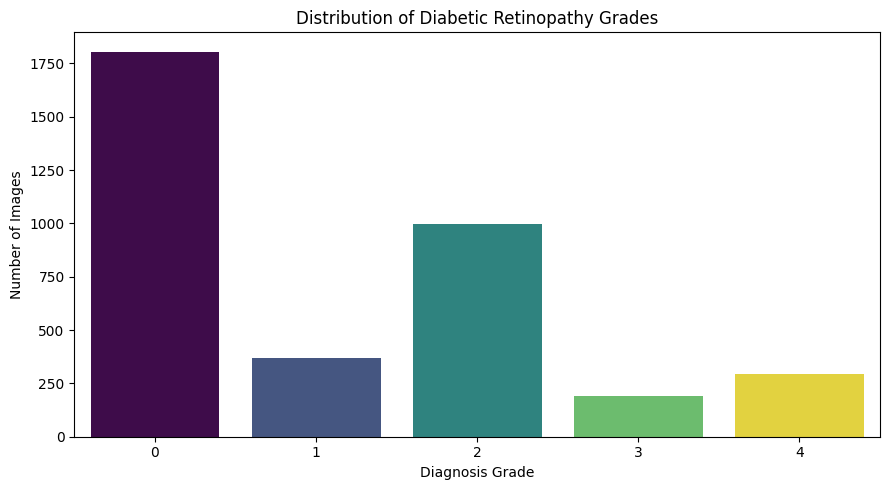

In [ ]:
# Class distribution visualization

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="diagnosis",
    hue="diagnosis",
    palette="viridis",
    legend=False
)

plt.title("Distribution of Diabetic Retinopathy Grades")
plt.xlabel("Diagnosis Grade")
plt.ylabel("Number of Images")
plt.xticks([0, 1, 2, 3, 4])

plt.tight_layout()
plt.show()

## 2. Class Distribution Analysis

The dataset contains five diabetic retinopathy severity grades.

The distribution is imbalanced, with Grade 0 representing
the largest class and Grade 3 representing the smallest.

This imbalance may affect model performance, particularly
for the minority classes.

We will investigate class weighting and use stratified
data splitting to address this challenge.

In [ ]:
# Calculate class percentages

class_counts = df["diagnosis"].value_counts().sort_index()

class_percentages = (
    df["diagnosis"].value_counts(normalize=True).sort_index() * 100
)

class_summary = pd.DataFrame({
    "Number of Images": class_counts,
    "Percentage": class_percentages.round(2)
})

class_summary

,Number of Images,Percentage
diagnosis,,
0,1805,49.29
1,370,10.10
2,999,27.28
3,193,5.27
4,295,8.06


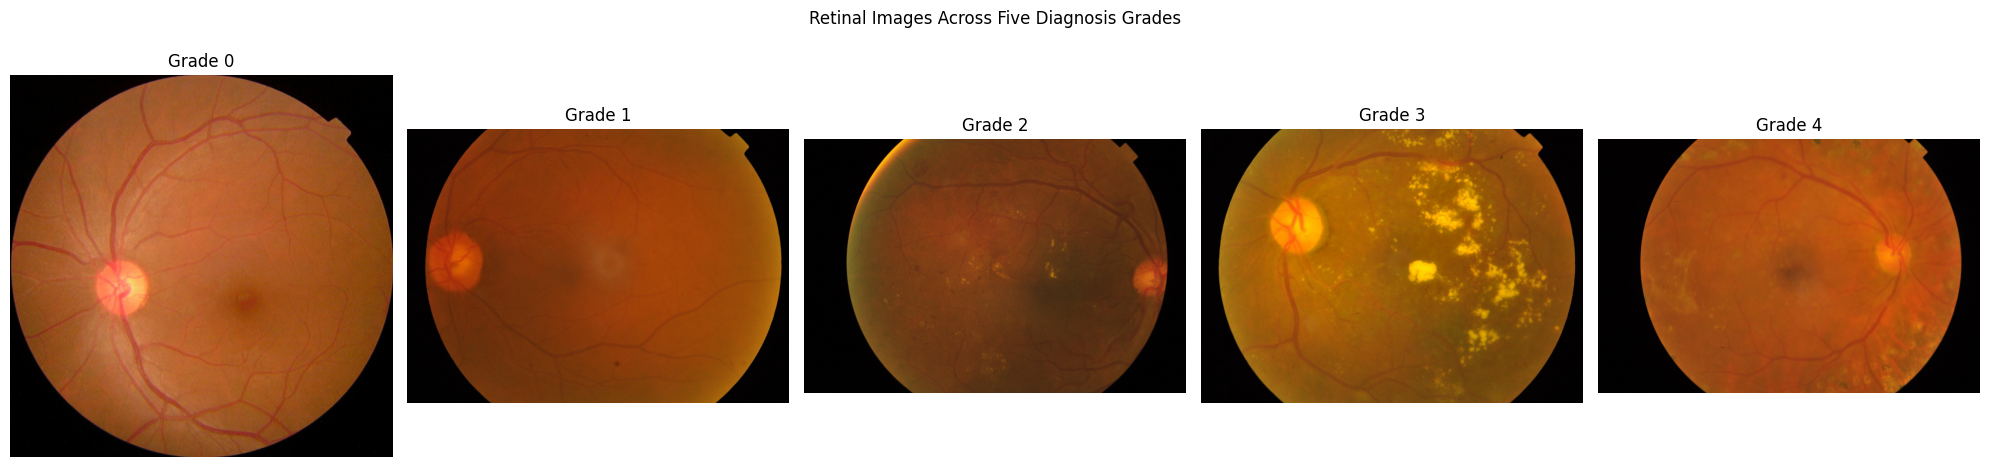

In [ ]:
# Display one retinal image from each diagnosis class

fig, axes = plt.subplots(1, 5, figsize=(20, 5))

for grade in range(5):

    sample = df[df["diagnosis"] == grade].iloc[0]

    image_path = TRAIN_IMAGES / f"{sample['id_code']}.png"

    image = Image.open(image_path).convert("RGB")

    axes[grade].imshow(image)
    axes[grade].set_title(f"Grade {grade}")
    axes[grade].axis("off")

plt.suptitle("Retinal Images Across Five Diagnosis Grades")
plt.tight_layout()
plt.show()

## 3. Retinal Image Quality and Dimensions

This section investigates the dimensions, color modes,
and image integrity of the APTOS training images.

Understanding image properties helps determine the
appropriate preprocessing strategy before model training.

In [ ]:
# Inspect image dimensions and color modes

image_info = []

for _, row in df.iterrows():
    image_path = TRAIN_IMAGES / f"{row['id_code']}.png"

    with Image.open(image_path) as img:
        image_info.append({
            "id_code": row["id_code"],
            "diagnosis": row["diagnosis"],
            "width": img.width,
            "height": img.height,
            "mode": img.mode,
            "format": img.format
        })

image_df = pd.DataFrame(image_info)

print("Total images inspected:", len(image_df))

print("\nImage dimensions:")
print(image_df[["width", "height"]].describe())

print("\nImage color modes:")
print(image_df["mode"].value_counts())

print("\nImage formats:")
print(image_df["format"].value_counts())

print("\nImages with different dimensions:")
print(image_df.groupby(["width", "height"]).size().sort_values(ascending=False).head(10))

Total images inspected: 3662

Image dimensions:
             width       height
count  3662.000000  3662.000000
mean   2015.176679  1526.830147
std     884.301940   542.663120
min     474.000000   358.000000
25%    1050.000000  1050.000000
50%    2144.000000  1536.000000
75%    2588.000000  1958.000000
max    4288.000000  2848.000000

Image color modes:
mode
RGB    3662
Name: count, dtype: int64

Image formats:
format
PNG    3662
Name: count, dtype: int64

Images with different dimensions:
width  height
1050   1050      974
2416   1736      638
2588   1958      533
3216   2136      410
2048   1536      351
819    614       287
3388   2588      141
1504   1000       92
1844   1226       61
4288   2848       52
dtype: int64


In [ ]:
# Check for missing or unreadable image files

missing_images = []
corrupted_images = []

for image_id in df["id_code"]:
    image_path = TRAIN_IMAGES / f"{image_id}.png"

    if not image_path.exists():
        missing_images.append(image_id)
        continue

    try:
        with Image.open(image_path) as img:
            img.verify()
    except Exception:
        corrupted_images.append(image_id)

print("Missing images:", len(missing_images))
print("Unreadable images:", len(corrupted_images))

Missing images: 0
Unreadable images: 0


## 4. Image Aspect Ratio Analysis

The training images have different dimensions.

This section examines their aspect ratios to determine
whether resizing directly to a square could distort
important retinal structures.

We will use aspect-ratio-preserving preprocessing
where necessary.

Aspect ratio statistics:
count    3662.000000
mean        1.283818
std         0.182116
min         1.000000
25%         1.000000
50%         1.333333
75%         1.391705
max         1.505618
Name: aspect_ratio, dtype: float64

Square images: 974

Landscape images: 2688

Portrait images: 0


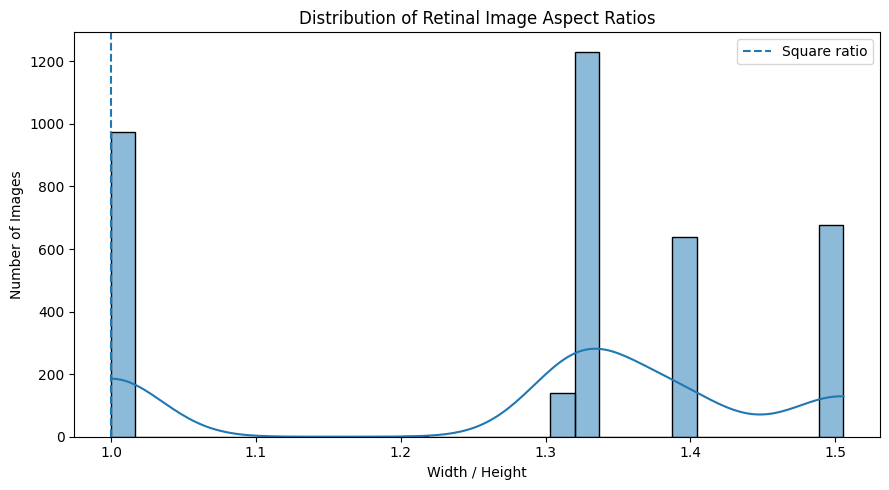

In [ ]:
# Calculate image aspect ratios

image_df["aspect_ratio"] = (
    image_df["width"] / image_df["height"]
)

print("Aspect ratio statistics:")
print(image_df["aspect_ratio"].describe())

print("\nSquare images:",
      (image_df["aspect_ratio"] == 1).sum())

print("\nLandscape images:",
      (image_df["aspect_ratio"] > 1).sum())

print("\nPortrait images:",
      (image_df["aspect_ratio"] < 1).sum())

# Visualize aspect ratios

plt.figure(figsize=(9, 5))

sns.histplot(
    data=image_df,
    x="aspect_ratio",
    bins=30,
    kde=True
)

plt.axvline(1.0, linestyle="--", label="Square ratio")

plt.title("Distribution of Retinal Image Aspect Ratios")
plt.xlabel("Width / Height")
plt.ylabel("Number of Images")
plt.legend()

plt.tight_layout()
plt.show()

## 5. Image Preprocessing Strategy

We will prepare retinal images for MobileNetV2 using:

1. RGB color conversion.
2. Aspect-ratio-preserving resizing.
3. Black padding to create square images.
4. Resizing to 224 × 224 pixels.

The preprocessing function will be tested on sample
images before applying it to the complete dataset.

In [ ]:
from PIL import ImageOps

IMAGE_SIZE = (224, 224)

def preprocess_image(image_path, size=IMAGE_SIZE):
    """
    Convert a retinal image to RGB, preserve its
    aspect ratio, pad it to a square, and resize it.
    """
    with Image.open(image_path) as img:
        img = img.convert("RGB")

        processed = ImageOps.pad(
            img,
            size,
            method=Image.Resampling.LANCZOS,
            color=(0, 0, 0),
            centering=(0.5, 0.5)
        )

    return processed

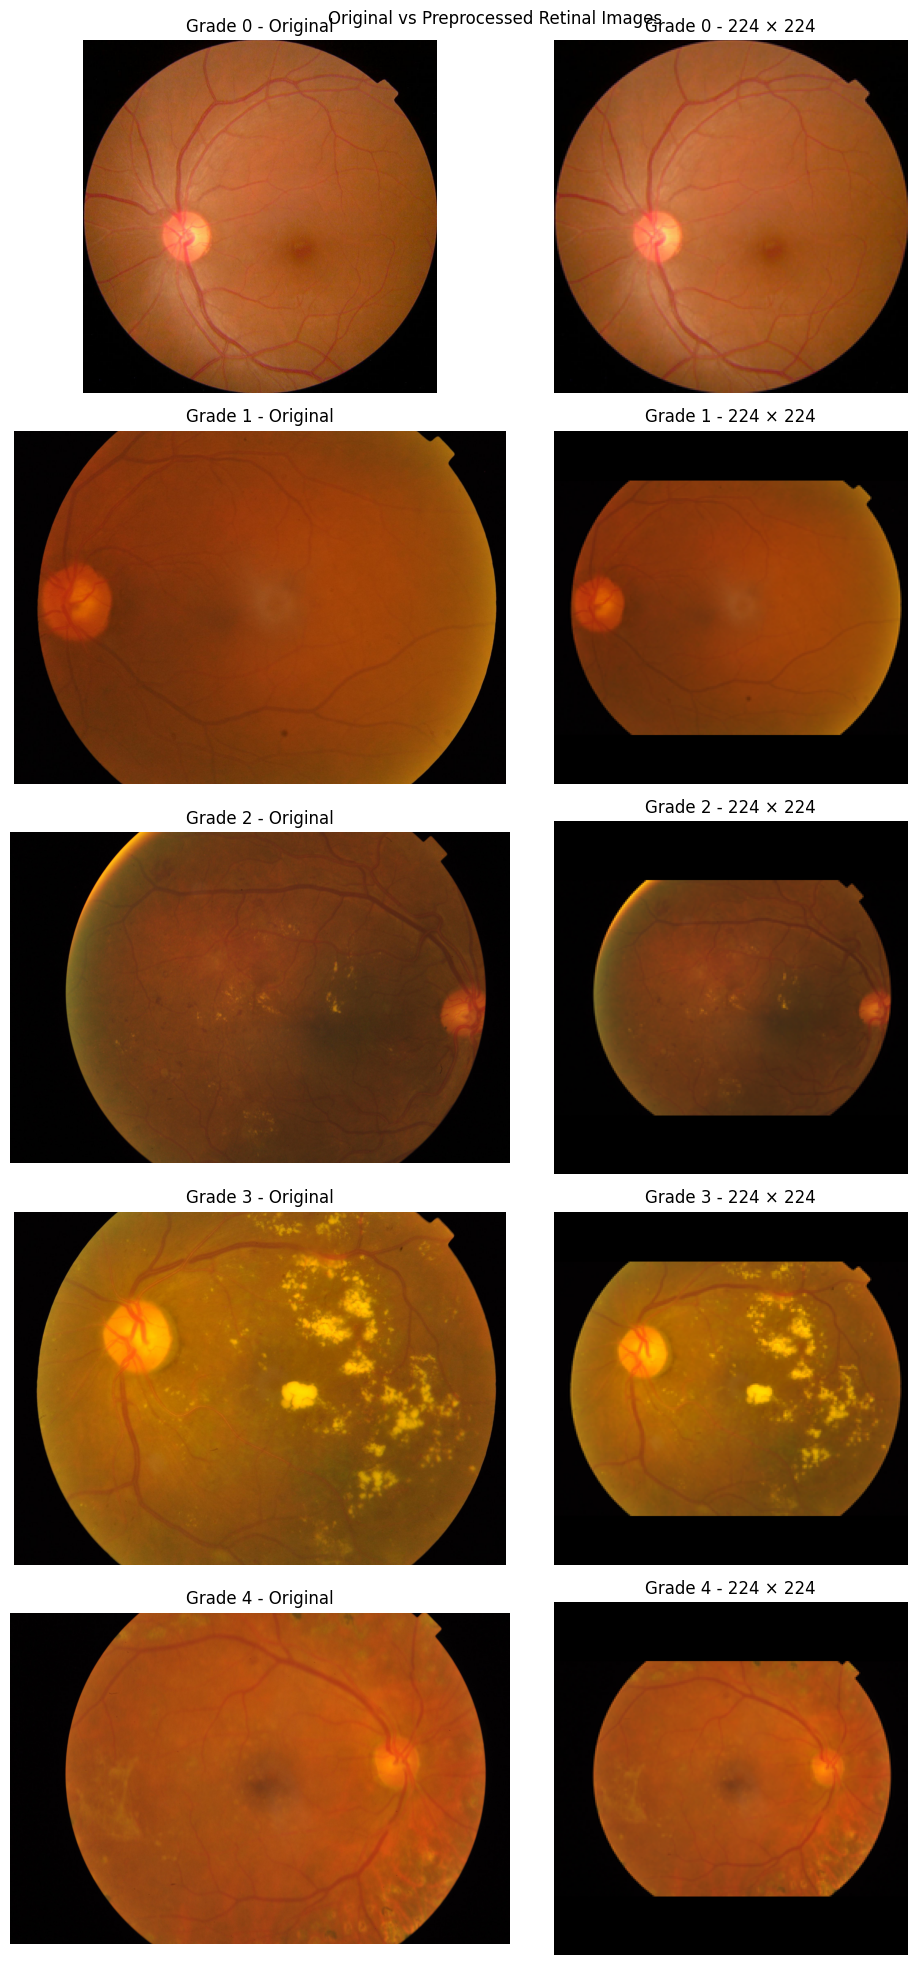

In [ ]:
fig, axes = plt.subplots(5, 2, figsize=(10, 20))

for grade in range(5):

    sample = df[df["diagnosis"] == grade].iloc[0]

    image_path = TRAIN_IMAGES / f"{sample['id_code']}.png"

    original = Image.open(image_path).convert("RGB")
    processed = preprocess_image(image_path)

    axes[grade, 0].imshow(original)
    axes[grade, 0].set_title(f"Grade {grade} - Original")

    axes[grade, 1].imshow(processed)
    axes[grade, 1].set_title(f"Grade {grade} - 224 × 224")

    axes[grade, 0].axis("off")
    axes[grade, 1].axis("off")

plt.suptitle("Original vs Preprocessed Retinal Images")
plt.tight_layout()
plt.show()

In [ ]:
# Verify processed image dimensions and properties

sample_path = TRAIN_IMAGES / f"{df.iloc[0]['id_code']}.png"

test_image = preprocess_image(sample_path)

print("Image size:", test_image.size)
print("Image mode:", test_image.mode)
print("Image data type:", np.array(test_image).dtype)
print("Minimum pixel value:", np.array(test_image).min())
print("Maximum pixel value:", np.array(test_image).max())

assert test_image.size == (224, 224)
assert test_image.mode == "RGB"

print("\nPreprocessing verification successful!")

Image size: (224, 224)
Image mode: RGB
Image data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255

Preprocessing verification successful!


## 6. Stratified Dataset Splitting

The dataset will be divided into training, validation,
and testing subsets.

- Training: 80%
- Validation: 10%
- Testing: 10%

Stratified splitting will preserve the class distribution
across all three subsets.

A fixed random state will ensure reproducibility.

In [ ]:
from sklearn.model_selection import train_test_split

# First split: 80% training, 20% temporary
train_df, temp_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df["diagnosis"],
    random_state=42
)

# Second split: divide temporary data equally
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["diagnosis"],
    random_state=42
)

# Reset indexes
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Testing samples:", len(test_df))

print("\nTotal samples:",
      len(train_df) + len(val_df) + len(test_df))

Training samples: 2929
Validation samples: 366
Testing samples: 367

Total samples: 3662


In [ ]:
# Compare class distributions across splits

split_distribution = pd.DataFrame({
    "Training": train_df["diagnosis"].value_counts(normalize=True),
    "Validation": val_df["diagnosis"].value_counts(normalize=True),
    "Testing": test_df["diagnosis"].value_counts(normalize=True)
}).sort_index() * 100

print("Class distribution across dataset splits:")
display(split_distribution.round(2))

Class distribution across dataset splits:


,Training,Validation,Testing
diagnosis,,,
0,49.30,49.18,49.32
1,10.11,10.11,10.08
2,27.28,27.32,27.25
3,5.26,5.46,5.18
4,8.06,7.92,8.17


## 7. Saving Dataset Splits

The training, validation, and testing image identifiers
and labels are saved for reproducibility.

The original retinal images remain unchanged.

In [ ]:
# Save dataset split metadata

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

train_df.to_csv(PROCESSED_DIR / "train_split.csv", index=False)
val_df.to_csv(PROCESSED_DIR / "validation_split.csv", index=False)
test_df.to_csv(PROCESSED_DIR / "test_split.csv", index=False)

print("Dataset splits saved successfully!")
print("Location:", PROCESSED_DIR)

Dataset splits saved successfully!
Location: /content/data/processed


## 8. TensorFlow Image Data Pipeline

We will create an image-loading pipeline using TensorFlow.

The pipeline will:
1. Load retinal images from disk.
2. Decode PNG images.
3. Convert images to RGB.
4. Resize images to 224 × 224 while preserving aspect ratio.
5. Normalize pixel values for MobileNetV2.
6. Batch and prefetch images for efficient training.

In [ ]:
import tensorflow as tf

# Configuration
IMAGE_SIZE = 224
BATCH_SIZE = 16
AUTOTUNE = tf.data.AUTOTUNE

# MobileNetV2 preprocessing
preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input


def load_and_preprocess_image(image_path, label):
    # Read image
    image = tf.io.read_file(image_path)

    # Decode PNG and ensure 3 color channels
    image = tf.image.decode_png(image, channels=3)

    # Preserve aspect ratio and resize
    image = tf.image.resize_with_pad(
        image,
        IMAGE_SIZE,
        IMAGE_SIZE
    )

    # Normalize for MobileNetV2
    image = preprocess_input(image)

    return image, label


def create_dataset(dataframe, shuffle=False):
    image_paths = [
        str(TRAIN_IMAGES / f"{image_id}.png")
        for image_id in dataframe["id_code"]
    ]

    labels = dataframe["diagnosis"].values.astype("int32")

    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=42
        )

    dataset = dataset.map(
        load_and_preprocess_image,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset

In [ ]:
train_dataset = create_dataset(train_df, shuffle=True)
validation_dataset = create_dataset(val_df)
test_dataset = create_dataset(test_df)

print("TensorFlow datasets created successfully!")

TensorFlow datasets created successfully!


In [ ]:
for images, labels in train_dataset.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())
    print("Labels:", labels.numpy())

Image batch shape: (16, 224, 224, 3)
Label batch shape: (16,)
Minimum pixel value: -1.0
Maximum pixel value: 1.0
Labels: [1 0 0 0 0 3 3 2 0 0 2 2 0 0 0 0]


## 9. MobileNetV2 model and Experiment 1

The pretrained MobileNetV2 backbone is frozen while the five-class classification head is trained. If an Experiment 1 model is already present in `/content/models`, it is loaded instead of retraining.

In [ ]:
EXPERIMENT1_PATH = MODEL_DIR / "mobilenetv2_experiment1.keras"
if EXPERIMENT1_PATH.exists():
    print("Loading saved Experiment 1...")
    model = tf.keras.models.load_model(EXPERIMENT1_PATH)
else:
    print("Building MobileNetV2...")
    base_model = tf.keras.applications.MobileNetV2(
        input_shape=(224, 224, 3), include_top=False, weights="imagenet"
    )
    base_model.trainable = False
    inputs = tf.keras.Input(shape=(224, 224, 3))
    x = base_model(inputs, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    outputs = tf.keras.layers.Dense(5, activation="softmax")(x)
    model = tf.keras.Model(inputs, outputs)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    model.summary()

base_model = next(layer for layer in model.layers
                  if isinstance(layer, tf.keras.Model) and "mobilenetv2" in layer.name.lower())
print("Backbone:", base_model.name)
print("Total parameters:", model.count_params())
print("Trainable parameters:", sum(int(np.prod(v.shape)) for v in model.trainable_variables))

Building MobileNetV2...
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,264,389 (8.64 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Backbone: mobilenetv2_1.00_224
Total parameters: 2264389
Trainable parameters: 6405


### 9.1 Class weights

Class weights are calculated from the training split only to account for the imbalanced grade distribution.

In [ ]:
classes = np.sort(train_df["diagnosis"].unique())
weights = compute_class_weight(class_weight="balanced", classes=classes,
                               y=train_df["diagnosis"].to_numpy())
class_weights = {int(k): float(v) for k, v in zip(classes, weights)}
print("Class weights:", class_weights)

Class weights: {0: 0.4056786703601108, 1: 1.979054054054054, 2: 0.7331664580725907, 3: 3.803896103896104, 4: 2.4822033898305085}


### 9.2 Train Experiment 1

If Experiment 1 was loaded from disk, this cell skips initial training. Otherwise, it trains up to 10 epochs and saves the best validation checkpoint.

In [ ]:
if not EXPERIMENT1_PATH.exists():
    initial_callbacks = [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.2, patience=2, min_lr=1e-6),
        tf.keras.callbacks.ModelCheckpoint(str(MODEL_DIR / "best_mobilenetv2_experiment1.keras"),
                                           monitor="val_loss", save_best_only=True)
    ]
    history_experiment1 = model.fit(train_dataset, validation_data=validation_dataset,
                                    epochs=10, class_weight=class_weights, callbacks=initial_callbacks)
    model = tf.keras.models.load_model(MODEL_DIR / "best_mobilenetv2_experiment1.keras")
    model.save(EXPERIMENT1_PATH)
    print("Experiment 1 saved:", EXPERIMENT1_PATH)
else:
    print("Experiment 1 already exists; skipping initial training.")

Epoch 1/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 259s 1s/step - accuracy: 0.5732 - loss: 1.3534 - val_accuracy: 0.6257 - val_loss: 0.8879 - learning_rate: 0.0010
Epoch 2/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 229s 1s/step - accuracy: 0.6668 - loss: 1.1069 - val_accuracy: 0.6749 - val_loss: 0.8245 - learning_rate: 0.0010
Epoch 3/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 263s 1s/step - accuracy: 0.6944 - loss: 1.0004 - val_accuracy: 0.6667 - val_loss: 0.8406 - learning_rate: 0.0010
Epoch 4/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 203s 1s/step - accuracy: 0.7286 - loss: 0.9109 - val_accuracy: 0.6967 - val_loss: 0.8427 - learning_rate: 0.0010
Epoch 5/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 218s 1s/step - accuracy: 0.7467 - loss: 0.8241 - val_accuracy: 0.6913 - val_loss: 0.7867 - learning_rate: 2.0000e-04
Epoch 6/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 200s 1s/step - accuracy: 0.7443 - loss: 0.8407 - val_accuracy: 0.7104 - val_loss: 0.7694 - learning_rate: 2.0000e-04
Epoch 7/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 216s 1s/step - accuracy: 0.7412 - 

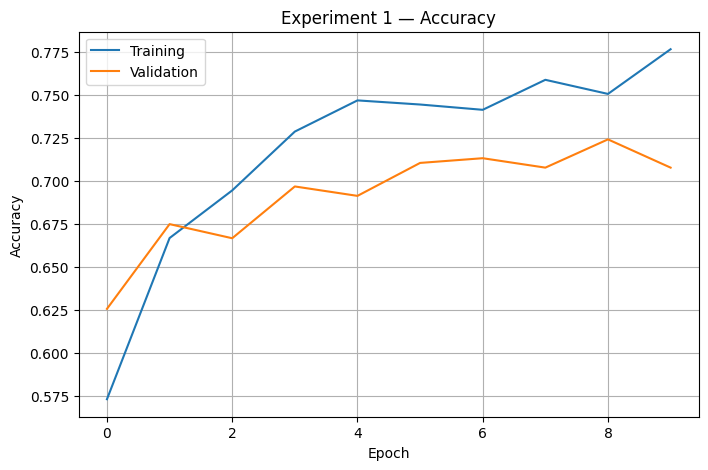

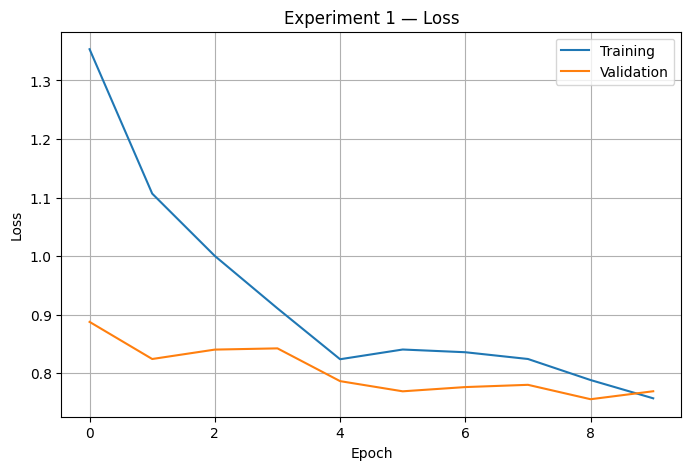

In [ ]:
if "history_experiment1" in globals():
    for metric, title in [("accuracy", "Accuracy"), ("loss", "Loss")]:
        plt.figure(figsize=(8,5))
        plt.plot(history_experiment1.history[metric], label="Training")
        plt.plot(history_experiment1.history["val_" + metric], label="Validation")
        plt.title("Experiment 1 — " + title)
        plt.xlabel("Epoch"); plt.ylabel(title); plt.legend(); plt.grid(True); plt.show()
else:
    print("Experiment 1 was loaded; no training history is available in this session.")

In [ ]:
from pathlib import Path

MODEL_DIR = Path("/content/models")

print("Models folder exists:", MODEL_DIR.exists())

if MODEL_DIR.exists():
    for file in MODEL_DIR.iterdir():
        print(file.name, "-", round(file.stat().st_size / (1024 * 1024), 2), "MB")

Models folder exists: True
best_mobilenetv2_experiment1.keras - 9.25 MB
mobilenetv2_experiment1.keras - 9.24 MB


## 10. Fine-tuning — Experiment 2

Unfreeze the final 30 MobileNetV2 layers, keep Batch Normalization layers frozen, and fine-tune with a smaller learning rate. Experiment 1 is kept unchanged for comparison.

In [ ]:
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
print("Fine-tuning configuration completed!")
print("Total parameters:", model.count_params())
print("Trainable parameters:", sum(int(np.prod(v.shape)) for v in model.trainable_variables))

Fine-tuning configuration completed!
Total parameters: 2264389
Trainable parameters: 6405


In [ ]:
EXPERIMENT2_PATH = MODEL_DIR / "mobilenetv2_experiment2_finetuned.keras"
fine_tune_callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.2, patience=2, min_lr=1e-7),
    tf.keras.callbacks.ModelCheckpoint(str(MODEL_DIR / "best_mobilenetv2_experiment2.keras"),
                                       monitor="val_loss", save_best_only=True)
]
fine_tune_history = model.fit(train_dataset, validation_data=validation_dataset,
                              epochs=10, class_weight=class_weights, callbacks=fine_tune_callbacks)
model = tf.keras.models.load_model(MODEL_DIR / "best_mobilenetv2_experiment2.keras")
model.save(EXPERIMENT2_PATH)
print("Fine-tuned Experiment 2 saved:", EXPERIMENT2_PATH)

Epoch 1/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 230s 1s/step - accuracy: 0.7743 - loss: 0.7680 - val_accuracy: 0.7186 - val_loss: 0.7589 - learning_rate: 1.0000e-05
Epoch 2/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 235s 1s/step - accuracy: 0.7542 - loss: 0.8043 - val_accuracy: 0.7158 - val_loss: 0.7589 - learning_rate: 1.0000e-05
Epoch 3/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 203s 1s/step - accuracy: 0.7651 - loss: 0.7822 - val_accuracy: 0.7186 - val_loss: 0.7579 - learning_rate: 1.0000e-05
Epoch 4/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 199s 1s/step - accuracy: 0.7596 - loss: 0.7782 - val_accuracy: 0.7186 - val_loss: 0.7578 - learning_rate: 1.0000e-05
Epoch 5/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 203s 1s/step - accuracy: 0.7545 - loss: 0.7884 - val_accuracy: 0.7186 - val_loss: 0.7571 - learning_rate: 1.0000e-05
Epoch 6/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 199s 1s/step - accuracy: 0.7579 - loss: 0.7898 - val_accuracy: 0.7158 - val_loss: 0.7552 - learning_rate: 1.0000e-05
Epoch 7/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 215s 1s/step - acc

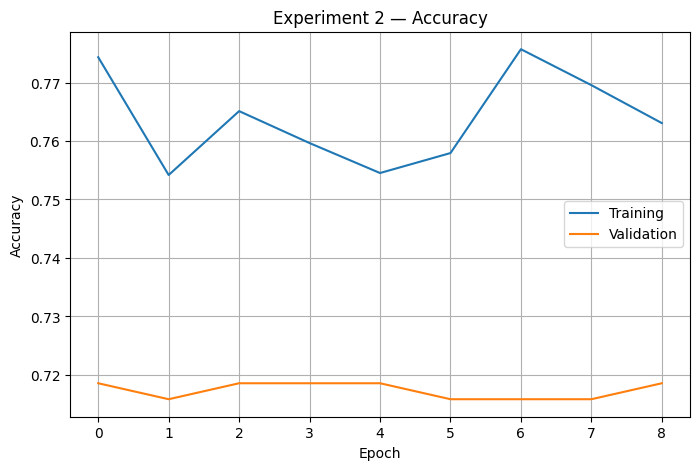

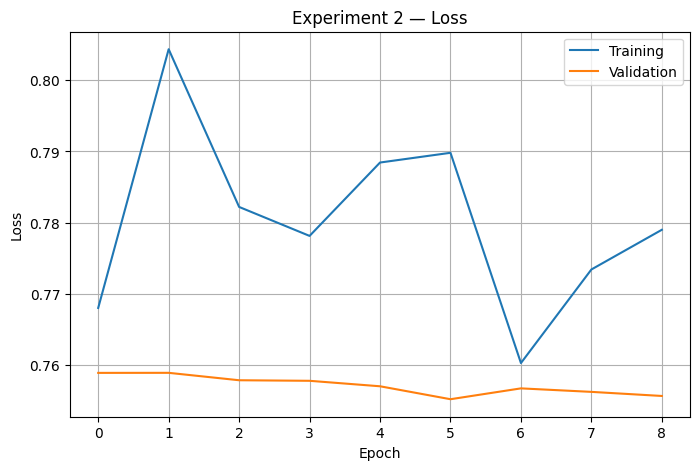

In [ ]:
for metric, title in [("accuracy", "Accuracy"), ("loss", "Loss")]:
    plt.figure(figsize=(8,5))
    plt.plot(fine_tune_history.history[metric], label="Training")
    plt.plot(fine_tune_history.history["val_" + metric], label="Validation")
    plt.title("Experiment 2 — " + title)
    plt.xlabel("Epoch"); plt.ylabel(title); plt.legend(); plt.grid(True); plt.show()

## 11. Held-out test evaluation

Evaluate the fine-tuned model on the held-out test split. This split is not used for training or fine-tuning.

In [ ]:
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, precision_recall_fscore_support,
                             cohen_kappa_score)

test_loss, _ = model.evaluate(test_dataset, verbose=1)
test_probabilities = model.predict(test_dataset, verbose=1)
y_pred = np.argmax(test_probabilities, axis=1)
y_true = test_df["diagnosis"].to_numpy()
accuracy = accuracy_score(y_true, y_pred)
precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(
    y_true, y_pred, average="macro", zero_division=0)
_, _, f1_weighted, _ = precision_recall_fscore_support(
    y_true, y_pred, average="weighted", zero_division=0)
quadratic_kappa = cohen_kappa_score(y_true, y_pred, weights="quadratic")
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {accuracy:.4f}")
print(f"Macro precision: {precision_macro:.4f}")
print(f"Macro recall: {recall_macro:.4f}")
print(f"Macro F1: {f1_macro:.4f}")
print(f"Weighted F1: {f1_weighted:.4f}")
print(f"Quadratic weighted kappa: {quadratic_kappa:.4f}")
print(classification_report(y_true, y_pred, labels=[0,1,2,3,4], zero_division=0))

23/23 ━━━━━━━━━━━━━━━━━━━━ 43s 2s/step - accuracy: 0.7575 - loss: 0.6155
23/23 ━━━━━━━━━━━━━━━━━━━━ 28s 1s/step
Test loss: 0.6155
Test accuracy: 0.7575
Macro precision: 0.6124
Macro recall: 0.6488
Macro F1: 0.6110
Weighted F1: 0.7659
Quadratic weighted kappa: 0.8337
              precision    recall  f1-score   support

           0       0.96      0.96      0.96       181
           1       0.44      0.57      0.49        37
           2       0.79      0.57      0.66       100
           3       0.32      0.68      0.43        19
           4       0.56      0.47      0.51        30

    accuracy                           0.76       367
   macro avg       0.61      0.65      0.61       367
weighted avg       0.79      0.76      0.77       367



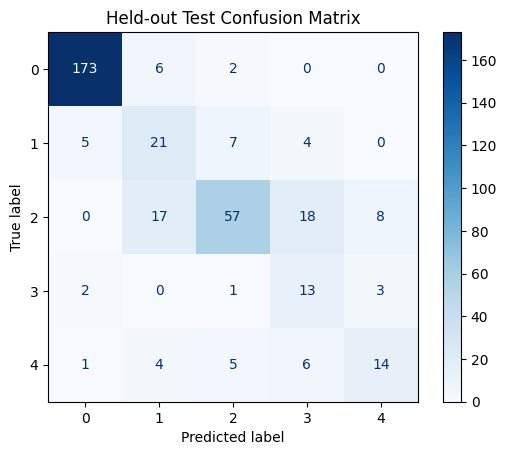

In [ ]:
cm = confusion_matrix(y_true, y_pred, labels=[0,1,2,3,4])
ConfusionMatrixDisplay(cm, display_labels=[0,1,2,3,4]).plot(cmap="Blues", values_format="d")
plt.title("Held-out Test Confusion Matrix")
plt.show()

## 12. Save and download final artifacts

Save the final fine-tuned model and the metrics actually measured on the held-out test split.

In [ ]:
import json
FINAL_MODEL_PATH = MODEL_DIR / "diabetesvision_mobilenetv2_final.keras"
METRICS_PATH = MODEL_DIR / "test_metrics.json"
model.save(FINAL_MODEL_PATH)
metrics = {
    "test_loss": float(test_loss), "test_accuracy": float(accuracy),
    "macro_precision": float(precision_macro), "macro_recall": float(recall_macro),
    "macro_f1": float(f1_macro), "weighted_f1": float(f1_weighted),
    "quadratic_weighted_kappa": float(quadratic_kappa), "test_samples": int(len(test_df))
}
with open(METRICS_PATH, "w") as f: json.dump(metrics, f, indent=4)
print(json.dumps(metrics, indent=4))
print("Saved:", FINAL_MODEL_PATH)

{
    "test_loss": 0.6154690980911255,
    "test_accuracy": 0.7574931880108992,
    "macro_precision": 0.6124081884741499,
    "macro_recall": 0.6488491731044799,
    "macro_f1": 0.611026738425972,
    "weighted_f1": 0.7658514531735121,
    "quadratic_weighted_kappa": 0.8336921712621772,
    "test_samples": 367
}
Saved: /content/models/diabetesvision_mobilenetv2_final.keras


In [1]:
from google.colab import files
files.download(str(FINAL_MODEL_PATH))
files.download(str(METRICS_PATH))

NameError: name 'FINAL_MODEL_PATH' is not defined

## Notes
- The competition's unlabeled `test.csv` is not used for model evaluation; evaluation uses the stratified held-out subset of labeled training data.
- Report actual metrics and training times from your own run; do not invent results.
- The model is for educational/research purposes and is not clinically validated.